# Home Credit Default Risk — Modeling

This notebook establishes an imbalanced-class benchmark and compares a small set of candidate models. All reusable data loading, preprocessing, resampling, and cross-validation logic lives in `src/models/modeling.py`; the notebook only orchestrates and communicates the analysis.

## Setup

Import the project utilities and modeling libraries. The project root is added to the Python path so the notebook can be run from either the repository root or the `notebooks/` directory.

In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit, cross_validate

project_root = Path.cwd().resolve()
if not (project_root / 'src').exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.models.modeling import RANDOM_STATE, compare_models, load_prepared_data

warnings.filterwarnings('ignore', category=UserWarning, module='lightgbm')
plt.style.use('seaborn-v0_8-whitegrid')

Load the prepared application-level data. `load_prepared_data()` explicitly excludes `SK_ID_CURR` from predictors while retaining test IDs for a later submission.

In [2]:
X, y, X_test, test_ids = load_prepared_data()

pd.DataFrame({
    'rows': [len(X), len(X_test)],
    'predictors': [X.shape[1], X_test.shape[1]],
}, index=['train', 'test']).rename_axis('split')

,rows,predictors
split,,
train,307507,177
test,48744,177


## 1. Benchmark: the majority-class model

A model that always predicts the non-default class is the minimum meaningful benchmark. It needs no predictors; using a one-column placeholder prevents unnecessary preprocessing and makes the benchmark nearly instantaneous.

Evaluate the majority classifier with the same three-fold stratified splits used later. Report both accuracy and ROC AUC so the class-imbalance effect is visible.

In [3]:
benchmark_folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
benchmark = cross_validate(
    DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE),
    np.zeros((len(y), 1)),
    y,
    cv=benchmark_folds,
    scoring={'auc': 'roc_auc', 'accuracy': 'accuracy'},
    n_jobs=-1,
)

benchmark_results = pd.DataFrame({
    'model': ['Majority class'],
    'mean_auc': [benchmark['test_auc'].mean()],
    'mean_accuracy': [benchmark['test_accuracy'].mean()],
})
benchmark_results.style.format({'mean_auc': '{:.3f}', 'mean_accuracy': '{:.3f}'})

,model,mean_auc,mean_accuracy
0,Majority class,0.500,0.919


With roughly 8% defaults, predicting every applicant as non-default is correct about 92% of the time, yet it assigns every applicant the same score and therefore has AUC 0.50. Accuracy rewards the dominant class and cannot distinguish useful risk ranking from this no-skill baseline. ROC AUC is the primary comparison metric because it evaluates how well a model ranks default risk across thresholds.

## 2. Candidate models

To keep this exploratory comparison practical, draw a reproducible 50,000-row stratified sample. This preserves the observed default rate while making three-fold evaluation of all four models manageable.

Create the development sample and define a small, interpretable predictor set. The small logistic model tests the value of the external-source scores plus core application characteristics against models using the full prepared feature set.

In [4]:
sample_split = StratifiedShuffleSplit(n_splits=1, train_size=50_000, random_state=RANDOM_STATE)
sample_indices, _ = next(sample_split.split(X, y))
X_sample = X.iloc[sample_indices].copy()
y_sample = y.iloc[sample_indices].copy()

small_predictors = [
    'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3',
    'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY',
    'DAYS_BIRTH', 'DAYS_EMPLOYED', 'CODE_GENDER',
    'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
]
missing_predictors = sorted(set(small_predictors).difference(X_sample.columns))
if missing_predictors:
    raise KeyError(f'Missing expected small-set predictors: {missing_predictors}')
X_small = X_sample.loc[:, small_predictors]

pd.DataFrame({
    'default_rate': [y.mean(), y_sample.mean()],
    'rows': [len(y), len(y_sample)],
}, index=['full training data', 'stratified sample']).style.format({'default_rate': '{:.2%}', 'rows': '{:,.0f}'})

,default_rate,rows
full training data,8.07%,"307,507"
stratified sample,8.07%,"50,000"


Plot the outcome mix in the development sample. Its close match to the full training rate is the visual check that stratified sampling retained the rare-event structure.

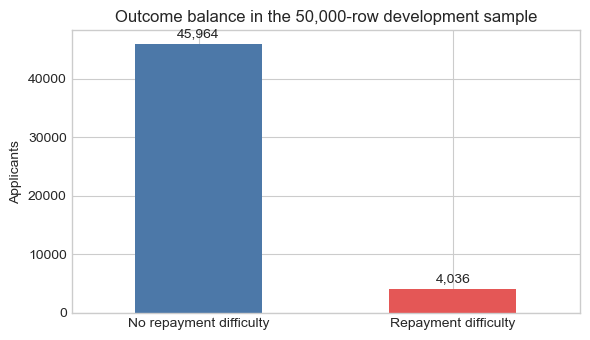

In [5]:
outcome_labels = y_sample.map({0: 'No repayment difficulty', 1: 'Repayment difficulty'})
ax = outcome_labels.value_counts().reindex(['No repayment difficulty', 'Repayment difficulty']).plot(
    kind='bar', color=['#4C78A8', '#E45756'], figsize=(6, 3.5), rot=0
)
ax.set(title='Outcome balance in the 50,000-row development sample', xlabel='', ylabel='Applicants')
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=3)
plt.tight_layout()
plt.show()

Fit and evaluate the candidate models. `compare_models()` constructs its preprocessing pipeline inside each cross-validation fold. Random forest and LightGBM each use `n_jobs=1`, while the reusable comparison function parallelizes across folds; this avoids nested parallelism and noisy training output.

In [6]:
small_logistic = LogisticRegression(
    max_iter=1_000, solver='liblinear', random_state=RANDOM_STATE
)
full_logistic = LogisticRegression(
    max_iter=1_000, solver='liblinear', random_state=RANDOM_STATE
)
random_forest = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=20,
    n_jobs=1, random_state=RANDOM_STATE
)
lightgbm = LGBMClassifier(
    n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
    colsample_bytree=0.8, n_jobs=1, random_state=RANDOM_STATE, verbosity=-1
)

small_results = compare_models({'Logistic regression (small set)': small_logistic}, X_small, y_sample)
full_results = compare_models(
    {
        'Logistic regression (all predictors)': full_logistic,
        'Random forest': random_forest,
        'LightGBM': lightgbm,
    },
    X_sample,
    y_sample,
)
comparison_results = pd.concat([small_results, full_results], ignore_index=True).sort_values(
    'mean_auc', ascending=False, ignore_index=True
)
comparison_results.style.format({
    'mean_auc': '{:.4f}', 'std_auc': '{:.4f}', 'mean_accuracy': '{:.4f}'
})

,model,mean_auc,std_auc,mean_accuracy
0,LightGBM,0.7433,0.0084,0.9194
1,Logistic regression (all predictors),0.7416,0.0082,0.9189
2,Random forest,0.7371,0.0103,0.9193
3,Logistic regression (small set),0.7308,0.0076,0.9191


LightGBM has the highest observed mean ROC AUC (**0.7433**), but its **0.0017** lead over all-predictor logistic regression (**0.7416**) is smaller than either model's fold standard deviation (about **0.008**). The two are therefore statistically tied on this development sample rather than meaningfully separated by this comparison. Both still materially beat the 0.50 no-skill benchmark (by 0.2433 and 0.2416 AUC, respectively); random forest (0.7371) and the compact logistic model (0.7308) also clear that benchmark. We carry LightGBM forward because it can accommodate missing values and nonlinear relationships, and it offers the most room for improvement through tuning; its similar ~0.919 accuracy is supporting context only, since the majority-class benchmark reaches about 0.92 accuracy without ranking risk at all.

Visualize the AUC comparison to make the ranking and fold-to-fold variation easier to scan than the table alone.

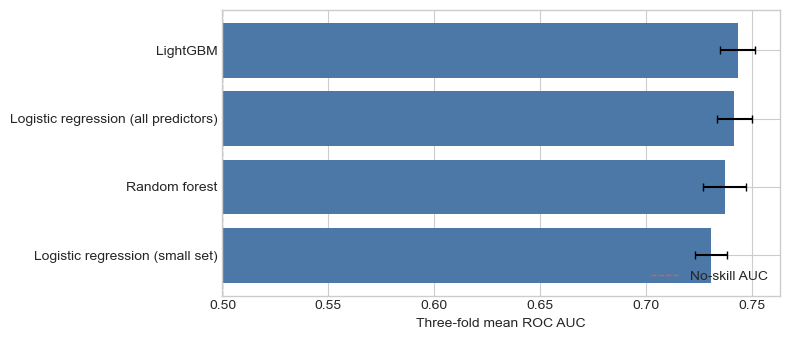

In [7]:
plot_results = comparison_results.sort_values('mean_auc')
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(plot_results['model'], plot_results['mean_auc'], xerr=plot_results['std_auc'], color='#4C78A8', capsize=3)
ax.axvline(0.50, color='#E45756', linestyle='--', linewidth=1, label='No-skill AUC')
ax.set(xlabel='Three-fold mean ROC AUC', xlim=(0.5, max(0.75, plot_results['mean_auc'].max() + 0.02)))
ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.show()

## 3. Class imbalance

The 8% default rate can make a learner focus too heavily on the non-default class. We compare no adjustment, random downsampling, random upsampling, SMOTE, and model-level class weights for the two Section 2 finalists: all-predictor logistic regression and LightGBM. Resampling is supplied through `build_model_pipeline()`, so it occurs only after each cross-validation training fold is formed.

Build the ten candidate configurations on the existing 50,000-row stratified sample. For LightGBM, `scale_pos_weight` is the training-sample ratio of non-default to default observations; for logistic regression, `class_weight='balanced'` applies inverse-frequency weights. Random forest is not included because LightGBM was the leading tree model from Section 2.

In [8]:
from src.models.modeling import build_model_pipeline

positive_weight = (y_sample == 0).sum() / (y_sample == 1).sum()

def make_logistic(class_weight=None):
    return LogisticRegression(
        max_iter=1_000, solver='liblinear', class_weight=class_weight, random_state=RANDOM_STATE
    )

def make_lightgbm(scale_pos_weight=None):
    parameters = dict(
        n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
        colsample_bytree=0.8, n_jobs=1, random_state=RANDOM_STATE, verbosity=-1
    )
    if scale_pos_weight is not None:
        parameters['scale_pos_weight'] = scale_pos_weight
    return LGBMClassifier(**parameters)

imbalance_models = {
    'Logistic regression | No adjustment': make_logistic(),
    'Logistic regression | Random downsampling': build_model_pipeline(make_logistic(), strategy='downsample'),
    'Logistic regression | Random upsampling': build_model_pipeline(make_logistic(), strategy='upsample'),
    'Logistic regression | SMOTE': build_model_pipeline(make_logistic(), strategy='SMOTE'),
    'Logistic regression | Class weights': make_logistic(class_weight='balanced'),
    'LightGBM | No adjustment': make_lightgbm(),
    'LightGBM | Random downsampling': build_model_pipeline(make_lightgbm(), strategy='downsample'),
    'LightGBM | Random upsampling': build_model_pipeline(make_lightgbm(), strategy='upsample'),
    'LightGBM | SMOTE': build_model_pipeline(make_lightgbm(), strategy='SMOTE'),
    'LightGBM | Class weights': make_lightgbm(scale_pos_weight=positive_weight),
}

imbalance_results = compare_models(imbalance_models, X_sample, y_sample)
model_parts = imbalance_results.pop('model').str.split(' | ', n=1, expand=True, regex=False)
imbalance_results.insert(0, 'model', model_parts[0])
imbalance_results.insert(1, 'adjustment', model_parts[1])
imbalance_results.style.format({
    'mean_auc': '{:.4f}', 'std_auc': '{:.4f}', 'mean_accuracy': '{:.4f}'
})

,model,adjustment,mean_auc,std_auc,mean_accuracy
0,LightGBM,No adjustment,0.7433,0.0084,0.9194
1,LightGBM,SMOTE,0.7431,0.0053,0.9191
2,LightGBM,Class weights,0.7418,0.0064,0.7964
3,Logistic regression,No adjustment,0.7416,0.0082,0.9189
4,Logistic regression,Class weights,0.7400,0.0096,0.6906
5,LightGBM,Random upsampling,0.7396,0.0057,0.7994
6,Logistic regression,Random upsampling,0.7386,0.0095,0.6921
7,LightGBM,Random downsampling,0.7368,0.0096,0.6733
8,Logistic regression,Random downsampling,0.7317,0.0092,0.6712
9,Logistic regression,SMOTE,0.7313,0.0094,0.7022


No class-imbalance adjustment improved ROC AUC on this sample. For LightGBM, the unadjusted model remains best at **0.7433**; SMOTE is effectively tied but lower at **0.7431** (−0.0002), while class weights (0.7418), random upsampling (0.7396), and random downsampling (0.7368) all reduce AUC. Logistic regression also performs best without adjustment at **0.7416**; class weights lower it by 0.0016, upsampling by 0.0030, downsampling by 0.0099, and SMOTE by 0.0103. We will therefore carry forward **unadjusted LightGBM** for tuning and threshold selection. The sharp drops in accuracy for several adjustments reflect changed decision thresholds, not better ranking, so they do not outweigh the AUC result.

## 4. Hyperparameter tuning

Section 3 found no AUC gain from resampling or class weighting, so this section tunes **unadjusted LightGBM** only. Randomized search explores a broad set of plausible configurations efficiently; it is preferable here to an exhaustive grid because the full parameter space would be unnecessarily expensive.

Tune approximately 20 randomly selected LightGBM configurations on a reproducible, stratified 5,000-row development subsample. Each candidate is evaluated with three-fold ROC AUC. The reusable `tune_model()` function keeps preprocessing inside each fold and uses no sampler or class weights.

In [9]:
from src.models.modeling import tune_model

tuning_model = LGBMClassifier(n_jobs=1, random_state=RANDOM_STATE, verbosity=-1)
tuning_space = {
    'model__n_estimators': [200, 300, 400, 500, 600],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.08, 0.10],
    'model__num_leaves': [15, 31, 63, 127],
    'model__max_depth': [-1, 4, 6, 8, 10],
    'model__min_child_samples': [10, 20, 40, 80, 120],
    'model__subsample': [0.70, 0.80, 0.90, 1.00],
    'model__colsample_bytree': [0.60, 0.75, 0.90, 1.00],
    'model__reg_alpha': [0.0, 0.001, 0.01, 0.1, 1.0],
    'model__reg_lambda': [0.0, 0.001, 0.01, 0.1, 1.0],
}
lightgbm_search = tune_model(
    model=tuning_model,
    param_distributions=tuning_space,
    X=X,
    y=y,
    strategy='none',
)

parameter_columns = [f'param_{name}' for name in tuning_space]
top_configurations = (
    pd.DataFrame(lightgbm_search.cv_results_)
    .nsmallest(5, 'rank_test_score')
    [['rank_test_score', 'mean_test_score', 'std_test_score', *parameter_columns]]
    .rename(columns={
        'rank_test_score': 'rank',
        'mean_test_score': 'mean_auc',
        'std_test_score': 'std_auc',
        **{f'param_{name}': name.removeprefix('model__') for name in tuning_space},
    })
)
top_configurations.style.format({'mean_auc': '{:.4f}', 'std_auc': '{:.4f}'})

,rank,mean_auc,std_auc,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,subsample,colsample_bytree,reg_alpha,reg_lambda
18,1,0.7397,0.0078,200,0.010000,31,6,120,1.000000,0.750000,0.100000,0.001000
4,2,0.7332,0.0076,400,0.010000,127,-1,120,0.900000,0.750000,0.100000,1.000000
8,3,0.7308,0.0042,400,0.030000,15,-1,40,0.900000,0.600000,1.000000,0.001000
19,4,0.7300,0.0123,400,0.010000,63,10,10,0.900000,0.600000,1.000000,0.010000
11,5,0.7280,0.0123,500,0.010000,63,6,10,0.900000,0.900000,0.001000,0.010000


Use the winning search parameters unchanged for a full-data, three-fold evaluation. This estimate is more stable than the 5,000-row tuning result because it uses every training applicant. After measuring CV AUC, fit the same unadjusted pipeline on all training rows so its fitted LightGBM estimator can provide feature importances.

In [10]:
from src.models.modeling import cross_validate_auc, fit_final_model

best_parameters = {
    name.removeprefix('model__'): value
    for name, value in lightgbm_search.best_params_.items()
}
best_lightgbm = LGBMClassifier(
    **best_parameters, n_jobs=1, random_state=RANDOM_STATE, verbosity=-1
)
full_cv_auc, full_cv_std = cross_validate_auc(best_lightgbm, X, y, cv=3)
final_lightgbm = fit_final_model(best_lightgbm, X, y, strategy='none')

full_evaluation = pd.DataFrame({
    'mean_auc': [full_cv_auc],
    'std_auc': [full_cv_std],
    'training_rows': [len(X)],
}, index=['Tuned LightGBM (full training data)'])
display(full_evaluation.style.format({'mean_auc': '{:.4f}', 'std_auc': '{:.4f}', 'training_rows': '{:,.0f}'}))

pd.DataFrame({
    'best_parameter': list(best_parameters),
    'value': list(best_parameters.values()),
})

,mean_auc,std_auc,training_rows
Tuned LightGBM (full training data),0.7452,0.0025,"307,507"


,best_parameter,value
0,subsample,1.000
1,reg_lambda,0.001
2,reg_alpha,0.100
3,num_leaves,31.000
4,n_estimators,200.000
5,min_child_samples,120.000
6,max_depth,6.000
7,learning_rate,0.010
8,colsample_bytree,0.750


Recover the transformed feature names from the fitted preprocessor and pair them with LightGBM's split-gain importances. Plotting the top 20 provides an interpretable summary of the signals the final fitted model used most often.

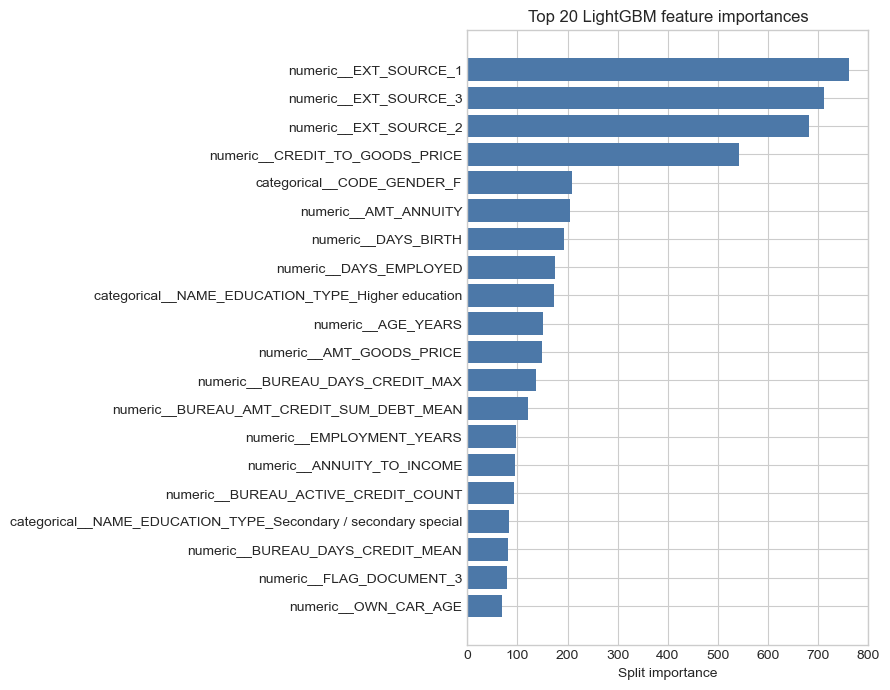

In [11]:
feature_names = final_lightgbm.named_steps['preprocessor'].get_feature_names_out()
feature_importances = pd.DataFrame({
    'feature': feature_names,
    'importance': final_lightgbm.named_steps['model'].feature_importances_,
}).sort_values('importance', ascending=False).head(20)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(feature_importances['feature'][::-1], feature_importances['importance'][::-1], color='#4C78A8')
ax.set(title='Top 20 LightGBM feature importances', xlabel='Split importance', ylabel='')
plt.tight_layout()
plt.show()

The randomized search selected a deliberately regularized configuration: **200 trees**, learning rate **0.01**, **31** leaves, maximum depth **6**, minimum child samples **120**, column subsampling **0.75**, `reg_alpha=0.1`, and `reg_lambda=0.001`. Its best 5,000-row search score was **0.7397 ± 0.0078** AUC. Using those parameters in three-fold CV over all 307,507 training rows produced **0.7452 ± 0.0025** AUC, a slightly higher and much more stable estimate than the 50,000-row comparison. The final full-data fit is therefore carried forward. The top importances are `EXT_SOURCE_1`, `EXT_SOURCE_3`, and `EXT_SOURCE_2`, followed by `CREDIT_TO_GOODS_PRICE`, `AMT_ANNUITY`, age/employment measures, and bureau-history summaries. These importances describe model use, not causal effects or approval policy.